# Dataset 4 — FoodData Central : EDA et classification

**Objectif du jour 2 :** dépouiller les données, expliquer les corrections et les associations, contrôler le découpage entraînement/test, entraîner un premier classificateur et faire une revue des résultats.

**Périmètre important :** le classificateur de ce notebook prédit `branded_food_category` pour explorer le dataset 4. Il ne remplace pas le modèle métier de réachat demandé dans le cahier des charges : celui-ci doit prédire `reordered` à partir de l’historique Instacart. Les segments de clients et les règles d’association doivent également être calculés à partir des paniers/commandes, pas de cette seule table nutritionnelle. Ces travaux nécessitent les données transactionnelles de l’équipe.

Ce notebook concerne le dataset 4 seul; il ne fusionne pas les datasets des autres membres, qui seront associés plus tard pour la visualisation. Si FoodData Central est présenté comme la quatrième source choisie, ses CSV pré-téléchargés ne démontrent pas à eux seuls l’exigence d’une collecte par scraping/crawling de pages HTML; cette conformité doit être justifiée séparément ou complétée par une source web appropriée.

Les CSV sont des tables relationnelles. On ne les concatène pas tous : une table de nutriments ou d’attributs peut contenir plusieurs lignes par aliment et créer des doublons.

In [ ]:
from pathlib import Path
import csv
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((path for path in candidates if (path / "preparer_donnees.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Impossible de localiser preparer_donnees.py")

RAW_DIR = ROOT / "data" / "raw"
OUT_DIR = ROOT / "data" / "processed"
TRAIN_PATH = OUT_DIR / "train.csv"
TEST_PATH = OUT_DIR / "test.csv"
REPORT_PATH = OUT_DIR / "quality_report.json"
REGENERER_PREPARATION = False

if REGENERER_PREPARATION or not (TRAIN_PATH.exists() and TEST_PATH.exists() and REPORT_PATH.exists()):
    subprocess.run([sys.executable, str(ROOT / "preparer_donnees.py")], cwd=ROOT, check=True)

with REPORT_PATH.open(encoding="utf-8") as report_file:
    rapport = json.load(report_file)

print("Dossier du projet :", ROOT)

## 1. Dépouillement des fichiers bruts

L’inventaire ci-dessous compte les enregistrements CSV (et non la ligne d’en-tête). Le scan complet du fichier `food_nutrient.csv` peut prendre quelques minutes.

In [2]:
inventaire = []
for chemin in sorted(RAW_DIR.glob("*.csv")):
    with chemin.open(encoding="utf-8-sig", newline="") as fichier:
        lecteur = csv.reader(fichier)
        colonnes = next(lecteur, [])
        nombre_lignes = sum(1 for _ in lecteur)
    inventaire.append({
        "fichier": chemin.name,
        "lignes": nombre_lignes,
        "colonnes": len(colonnes),
        "taille_Mo": round(chemin.stat().st_size / 1_000_000, 2),
    })

inventaire_df = pd.DataFrame(inventaire).sort_values("lignes", ascending=False)
display(inventaire_df)

,fichier,lignes,colonnes,taille_Mo
6,food_nutrient.csv,26201321,11,1506.16
2,food_attribute.csv,2481889,6,133.94
1,food.csv,2010212,8,377.99
0,branded_food.csv,2010212,21,960.72
9,food_update_log_entry.csv,2010212,3,133.69
15,sub_sample_food.csv,88508,2,1.75
7,food_nutrient_conversion_factor.csv,11641,2,0.20
8,food_portion.csv,10951,11,0.71
10,input_food.csv,6068,12,0.33
14,sample_food.csv,4109,1,0.04


## 2. Association des tables

`branded_food` est la table principale. `food` apporte la description par `fdc_id`. Les lignes de `food_nutrient` sont filtrées sur les produits retenus et les huit nutriments choisis; `nutrient.csv` sert à vérifier leurs noms et unités. Les autres tables ne sont pas ajoutées à cette classification, car elles sont hors cible ou risquent de multiplier les lignes.

In [3]:
print("Jointures appliquées :")
display(pd.DataFrame({"relation": rapport["joins"]}))

print("Tables non jointes pour cette tâche :")
display(pd.DataFrame({
    "table(s)": rapport["excluded_as_not_applicable_or_not_needed_for_this_branded_food_model"]
}))

resume = {
    "lignes brutes branded_food": rapport["source_branded_food_rows"],
    "UPC distincts après conservation de la version récente": rapport["latest_unique_upc_rows"],
    "dernières fiches sans catégorie retirées": rapport["latest_rows_missing_category"],
    "produits étiquetés retenus": rapport["rows_after_latest_version_and_category_filter"],
    "catégories cible": rapport["target_class_count"],
}
display(pd.Series(resume, name="valeur").to_frame())

Jointures appliquées :


,relation
0,branded_food.fdc_id = food.fdc_id (one-to-one)
1,"food_nutrient.fdc_id = branded_food.fdc_id, fi..."
2,nutrient.id = food_nutrient.nutrient_id (nutri...


Tables non jointes pour cette tâche :


,table(s)
0,food_attribute and food_attribute_type
1,food_portion and measure_unit
2,food_component
3,food_nutrient_conversion_factor and food_calor...
4,input_food
5,food_update_log_entry
6,microbe
7,sample_food and sub_sample_food


,valeur
lignes brutes branded_food,2010212
UPC distincts après conservation de la version récente,466727
dernières fiches sans catégorie retirées,227
produits étiquetés retenus,466500
catégories cible,353


## 3. Nettoyage, corrections et valeurs manquantes

Le script normalise les espaces et certains caractères Unicode, garde l’UPC comme texte, et choisit la dernière fiche par `modified_date` (égalité : plus grand `fdc_id`). Les lignes sans catégorie après ce choix sont retirées. Les mesures nutritionnelles absentes ne sont pas inventées; les montants invalides/négatifs sont laissés manquants. L’imputation sera apprise uniquement sur le train par le pipeline du modèle.

Le tableau suivant mesure les valeurs manquantes après nettoyage et association.

In [4]:
colonnes_auditees = rapport["feature_columns"] + [rapport["target_column"]]
manquants = pd.Series(0, index=colonnes_auditees, dtype="int64")
total_lignes = 0
for chemin in (TRAIN_PATH, TEST_PATH):
    for bloc in pd.read_csv(chemin, usecols=colonnes_auditees, chunksize=50_000):
        total_lignes += len(bloc)
        manquants = manquants.add(bloc.isna().sum(), fill_value=0).astype("int64")

qualite_manquants = pd.DataFrame({
    "valeurs_manquantes": manquants,
    "pourcentage": (manquants / total_lignes * 100).round(2),
}).sort_values("pourcentage", ascending=False)
display(qualite_manquants)

,valeurs_manquantes,pourcentage
fiber_g,78368,16.80
saturated_fat_g,65017,13.94
total_sugars_g,30892,6.62
brand_name,23459,5.03
carbohydrate_g,8823,1.89
sodium_mg,7988,1.71
energy_kcal,7705,1.65
brand_owner,6801,1.46
total_fat_g,6701,1.44
protein_g,6339,1.36


## 4. Exploration de la cible et segmentation

Le découpage est d’environ 80/20, stratifié et reproductible (`random_state=42`). Les UPC sont dédupliqués avant le découpage, puis les identifiants `fdc_id` et `gtin_upc` sont exclus des variables de modèle. Une catégorie avec un seul produit reste uniquement dans l’entraînement; chaque autre catégorie est représentée dans le test.

Train : 373,187 lignes | Test : 93,313 lignes
Catégories au total : 353 | représentées dans le test : 313


,produits (20 premières)
catégorie,
Candy,23162
"Popcorn, Peanuts, Seeds & Related Snacks",22350
Cheese,18581
Ice Cream & Frozen Yogurt,13691
Cookies & Biscuits,13643
"Chips, Pretzels & Snacks",12672
Chocolate,10811
"Pickles, Olives, Peppers & Relishes",10576
Breads & Buns,10543


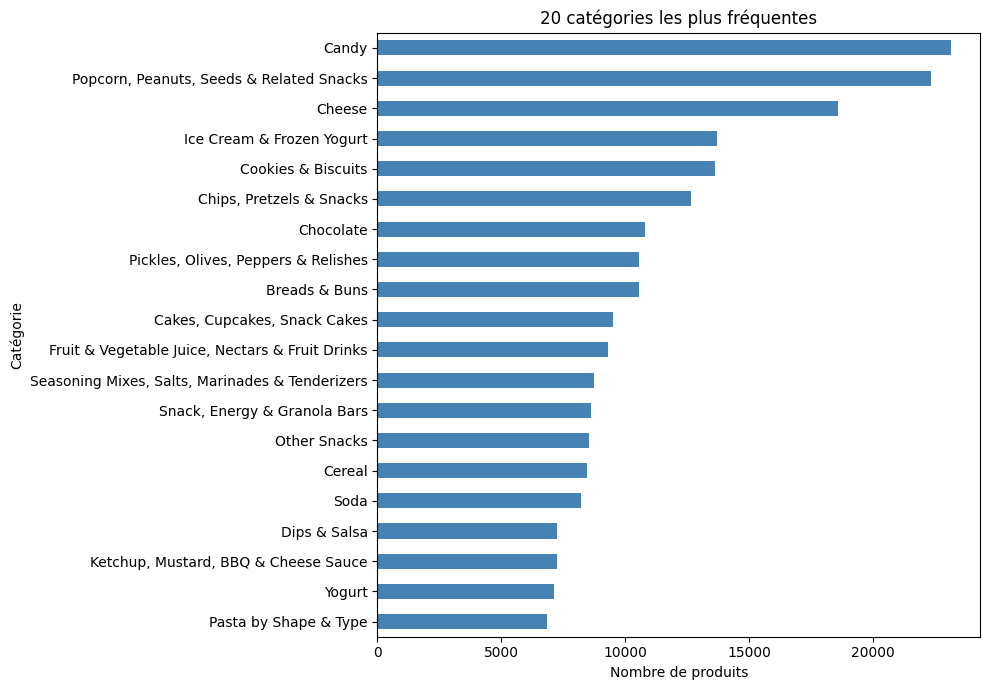

In [5]:
cible = rapport["target_column"]
train_y = pd.read_csv(TRAIN_PATH, usecols=[cible])[cible]
test_y = pd.read_csv(TEST_PATH, usecols=[cible])[cible]
frequences = pd.concat([train_y, test_y], ignore_index=True).value_counts()

print(f"Train : {len(train_y):,} lignes | Test : {len(test_y):,} lignes")
print(f"Catégories au total : {len(frequences)} | représentées dans le test : {test_y.nunique()}")
display(frequences.head(20).rename_axis("catégorie").to_frame("produits (20 premières)"))

frequences.head(20).sort_values().plot(kind="barh", figsize=(10, 7), color="steelblue")
plt.title("20 catégories les plus fréquentes")
plt.xlabel("Nombre de produits")
plt.ylabel("Catégorie")
plt.tight_layout()
plt.show()

In [6]:
train_columns = set(pd.read_csv(TRAIN_PATH, nrows=0).columns)
test_columns = set(pd.read_csv(TEST_PATH, nrows=0).columns)
categories_train = set(train_y.unique())
categories_test = set(test_y.unique())
categories_uniques = set(frequences[frequences == 1].index)

assert len(train_y) + len(test_y) == rapport["rows_after_latest_version_and_category_filter"]
assert train_columns == test_columns
assert "fdc_id" not in train_columns and "gtin_upc" not in train_columns
assert categories_test.issubset(categories_train)
assert set(frequences.index) - categories_test == categories_uniques

print("Contrôles réussis : pas de catégorie test absente du train; les seules catégories absentes du test sont les catégories uniques.")
print("Taux test réel :", round(len(test_y) / (len(train_y) + len(test_y)) * 100, 3), "%")

Contrôles réussis : pas de catégorie test absente du train; les seules catégories absentes du test sont les catégories uniques.
Taux test réel : 20.003 %


## 5. Exploration des variables numériques

Les unités restent celles fournies par FoodData Central (par exemple kcal, g et mg); on ne mélange pas ces grandeurs et on ne prétend pas les convertir en valeurs par portion.

,count,mean,std,min,50%,90%,99%,max
serving_size,466498.0,83.79,100.31,0.0,42.00,240.00,454.00,10800.0
energy_kcal,458795.0,277.48,554.12,0.0,275.00,515.00,800.00,226000.0
protein_g,460161.0,7.55,21.50,0.0,4.55,19.64,40.00,3400.0
total_fat_g,459799.0,12.79,26.36,0.0,5.76,32.50,86.67,4000.0
carbohydrate_g,457677.0,34.54,51.78,0.0,24.53,76.47,100.00,12700.0
total_sugars_g,435608.0,16.97,31.24,0.0,6.25,50.00,90.48,5800.0
sodium_mg,458512.0,1682.90,115268.20,0.0,258.00,1000.00,12000.00,40000000.0
fiber_g,388132.0,2.92,9.90,0.0,1.40,7.10,22.20,2468.9
saturated_fat_g,401483.0,5.12,14.70,0.0,2.14,14.29,28.57,2402.4


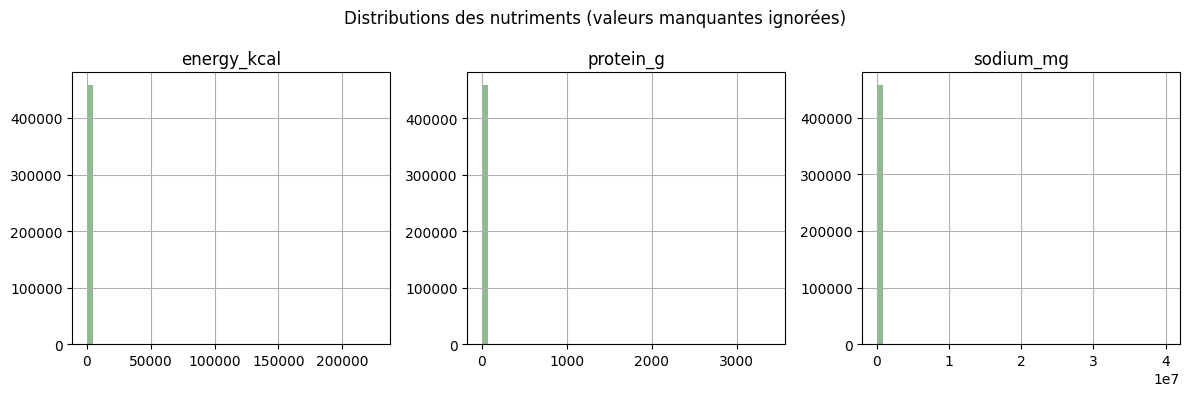

In [7]:
variables_numeriques = [
    "serving_size", "energy_kcal", "protein_g", "total_fat_g",
    "carbohydrate_g", "total_sugars_g", "sodium_mg", "fiber_g",
    "saturated_fat_g",
]
blocs_numeriques = [
    pd.read_csv(chemin, usecols=variables_numeriques)
    for chemin in (TRAIN_PATH, TEST_PATH)
]
numeriques = pd.concat(blocs_numeriques, ignore_index=True)
display(numeriques.describe(percentiles=[0.5, 0.9, 0.99]).T.round(2))

numeriques[["energy_kcal", "protein_g", "sodium_mg"]].hist(
    bins=50, figsize=(12, 4), layout=(1, 3), color="darkseagreen"
)
plt.suptitle("Distributions des nutriments (valeurs manquantes ignorées)")
plt.tight_layout()
plt.show()

## 6. Modèle de classification et évaluation

Le premier modèle est un **Complement Naive Bayes** : TF-IDF pour la description et les ingrédients, encodage one-hot pour les champs de marque/unité, imputation médiane et mise à l’échelle des variables numériques. Le pipeline apprend son vocabulaire, ses encodages et ses imputations sur le train seulement. Le test ne sert qu’à l’évaluation.

Une baseline « toujours prédire la catégorie majoritaire » sert de comparaison. L’accuracy seule peut masquer les catégories rares; on rapporte aussi le F1 macro et le F1 pondéré. Ce modèle est un premier repère, pas encore un modèle optimisé.

In [8]:
METRICS_PATH = OUT_DIR / "classification_metrics.json"
REENTRAINER_MODELE = False
if REENTRAINER_MODELE or not METRICS_PATH.exists():
    subprocess.run([sys.executable, str(ROOT / "entrainer_classification.py")], cwd=ROOT, check=True)

with METRICS_PATH.open(encoding="utf-8") as metrics_file:
    metriques = json.load(metrics_file)
display(pd.Series({
    "Modèle": metriques["modele"],
    "Accuracy modèle": round(metriques["accuracy"], 4),
    "F1 macro modèle": round(metriques["f1_macro"], 4),
    "F1 pondéré modèle": round(metriques["f1_pondere"], 4),
    "Balanced accuracy modèle": round(metriques["balanced_accuracy"], 4),
    "Accuracy baseline majorité": round(metriques["baseline_classe_majoritaire"]["accuracy"], 4),
    "Secondes d’entraînement": metriques["temps_entrainement_secondes"],
}, name="résultat"))

Modèle                        ComplementNB avec TF-IDF, variables catégoriel...
Accuracy modèle                                                          0.7672
F1 macro modèle                                                          0.4508
F1 pondéré modèle                                                        0.7527
Balanced accuracy modèle                                                 0.4224
Accuracy baseline majorité                                               0.0497
Secondes d’entraînement                                                   51.92
Name: résultat, dtype: object

In [9]:
with (OUT_DIR / "classification_par_categorie.json").open(encoding="utf-8") as class_file:
    rapport_classes = json.load(class_file)

par_categorie = pd.DataFrame.from_dict(
    {
        nom: scores
        for nom, scores in rapport_classes.items()
        if isinstance(scores, dict) and nom not in {"macro avg", "weighted avg"}
    },
    orient="index",
)
display(par_categorie.sort_values("f1-score").head(15))

,precision,recall,f1-score,support
Yogurt/Yogurt Substitutes (Perishable),0.0,0.0,0.0,1.0
Antipasto,0.0,0.0,0.0,1.0
Biscuits Plain/Sweet,0.0,0.0,0.0,1.0
Aquatic Invertebrates/Fish/Shellfish/Seafood Combination,0.0,0.0,0.0,1.0
Breakfast Cereals - Hot And Cold,0.0,0.0,0.0,6.0
"Breakfast Sandwiches, Biscuits & Meals",0.0,0.0,0.0,60.0
Bread - Incl. Buns And Rolls,0.0,0.0,0.0,3.0
Cakes - Sweet (Frozen),0.0,0.0,0.0,8.0
Taco Shells,0.0,0.0,0.0,1.0
Vegetable Based Products / Meals - Not Ready to Eat (Frozen),0.0,0.0,0.0,10.0


## 7. Revue et limites

- Vérifier que le modèle dépasse la baseline, en particulier sur le F1 macro, qui donne davantage de poids aux catégories rares.
- Examiner les catégories aux plus faibles F1 dans le tableau ci-dessus; certaines ont peu de produits ou des libellés ambigus.
- Les nutriments sont parfois absents; les valeurs ont été imputées dans le pipeline sans regarder le test.
- Le choix de la dernière fiche par UPC évite les doublons entre train et test, mais une vérification métier des anciennes fiches aux catégories divergentes reste utile.
- Le résultat est une première classification exploratoire du dataset 4, pas le modèle de réachat attendu pour Panier Vert.
- Le clustering des clients/produits et les règles Apriori/FP-Growth restent à réaliser sur les données de commandes; la fusion avec les autres datasets pour les visualisations viendra séparément.
- Les fichiers FoodData Central présents ici ne prouvent pas à eux seuls la collecte obligatoire d’une source par scraping/crawling HTML, si cette base est retenue comme source 4.
- La fusion avec les datasets des autres membres pour les visualisations viendra séparément; les identifiants de jointure devront alors être définis avec l’équipe.

Fichiers produits : `train.csv`, `test.csv`, `quality_report.json`, `modele_classification.joblib`, `classification_metrics.json` et `classification_par_categorie.json` dans `data/processed`.